# Setup

In [1]:
# Standard library
import json
from pathlib import Path
from unittest.mock import patch

# Arrays, dates and figures
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reusable project tools
from agentic_ts import module02_panel as panel
from agentic_ts import module02_panel_publication as publication
from agentic_ts import module02_workflow as workflow
from agentic_ts import routing_forecasting as numerical
from agentic_ts.forecasting import FrozenJSON
from agentic_ts.module01_assets import PublicationAssets

The code initializes a workspace for time-series analysis and forecasting workflows by importing standard libraries, data science frameworks, and specialized components from the `agentic_ts` package.

Standard library imports provide utilities for JSON processing, file system path management via `pathlib`, and unit testing mocks. The inclusion of NumPy, Pandas, and Matplotlib establishes the environment for numerical computation, data manipulation, and visualization.

The custom modules imported from `agentic_ts` facilitate specific analytical tasks:
* **Workflow and Panel Management:** Tools for orchestrating processes (`module02_workflow`) and handling panel-style data (`module02_panel`).
* **Forecasting Logic:** Components for numerical routing (`routing_forecasting`) and a specialized `FrozenJSON` data structure.
* **Publication Utilities:** Modules and assets intended for generating or managing publication-ready content (`module02_panel_publication`, `PublicationAssets`).


In [2]:
class CFG:
    root = Path.cwd()
    example_folder = root / "examples/module02_panel"
    graph_folder = root / "graphs/module02-panel"
    run_mode = "full_recompute"
    img_dim1 = 20
    img_dim2 = 10
    publication_scale = 0.65
    export_dpi = 180
    table_fontsize = 13
    table_decimals = 2
    table_header_color = "#25455d"
    table_alternate_color = "#eaf0f4"
    table_wrap_chars = 100
    table_line_height = 0.22
    table_min_height = 1.5
    SEED = 42

plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (CFG.img_dim1, CFG.img_dim2)
np.random.seed(CFG.SEED)
assert (CFG.root / "pyproject.toml").is_file(), "Run from the repository root"
assert CFG.run_mode == "full_recompute"

This code establishes a centralized configuration environment and enforces specific execution constraints to ensure reproducibility and visual consistency in data output.

The `CFG` class serves as a single source of truth for various parameters:
* **Path Management:** It defines the project root based on the current working directory and constructs paths for example files and generated graphs.
* **Execution Control:** The `run_mode` variable specifies how the subsequent logic should behave, specifically defaulting to a state where all computations are recalculated.
* **Visual Styling:** A large set of constants defines the aesthetics for figures (dimensions, DPI, scaling) and tables (font size, decimal precision, hex colors, and cell dimensions). This suggests the workflow is designed to produce standardized, publication-ready visual assets.

Global settings are applied using these configuration values to prepare the environment for data processing and visualization:
* **Reproducibility:** Setting `np.random.seed` ensures that any stochastic operations within NumPy yield deterministic results across different runs.
* **Plotting Defaults:** The code configures Matplotlib to use a specific Seaborn style and applies the dimensions defined in `CFG` to all subsequent figure creation.

The script includes two assertions that act as safety guardrails:
1. It verifies that the execution is occurring from the repository root by checking for the presence of a `pyproject.toml` file. 
2. It enforces that `run_mode` is strictly set to `"full_recompute"`. If these conditions are not met, the script terminates with an error to prevent running in an unintended state or directory.

# Utils

In [3]:
def read_record(name):
    return panel.record(name)

protocol = read_record("protocol.json")
author_run = read_record("author_run.json")
assert workflow.digest(protocol) == author_run["protocol_hash"]
assets = PublicationAssets(CFG, workflow.digest(protocol), prefix="atsf02",
                           post="a02-post-new.md", sidecar_dir="examples/module02_panel")
no_inference = patch.object(workflow.OllamaClient, "complete", side_effect=AssertionError("No LLM call belongs here"))
inference_guard = no_inference.start()
print("Study version:", panel.VERSION)

Study version: module02-panel-v1


This code validates the integrity of an existing analytical run and prepares asset management while strictly prohibiting any Large Language Model (LLM) involvement during execution.

The logic proceeds through three main phases:

**Integrity Validation**
The function `read_record` retrieves configuration data from JSON files via the `panel` module. The code loads a `protocol` object and an `author_run` record, which contains metadata from a previous execution. An assertion verifies that the cryptographic digest of the current `protocol` matches the `protocol_hash` stored in the `author_run`. This ensures that the parameters used in the current session are identical to those used during the original run, preventing inconsistent results caused by configuration changes.

**Asset Initialization**
Once validated, a `PublicationAssets` object is instantiated. This object uses the configuration settings (`CFG`), the unique protocol digest, and specific naming parameters (a prefix and a Markdown filename) to manage files intended for publication. It also defines a sidecar directory where related assets are stored.

**Inference Guarding**
To ensure the execution remains deterministic and free from stochastic LLM outputs, the code implements a safety mechanism using `unittest.mock.patch`. By patching `workflow.OllamaClient.complete`, the script intercepts any attempt to call the LLM's completion method. If any part of the subsequent workflow attempts an inference call, the program will immediately raise an `AssertionError`. This "inference guard" serves as a programmatic constraint to ensure this specific module operates without external model intervention.

Finally, the code prints the version identifier of the current study via `panel.VERSION`.

In [4]:
print("Numerical configuration:", panel.CFG)
print("Candidate families:", numerical.FAMILIES)
print("Versions:", numerical.package_versions())
print("Stores:", panel.STORES)

Numerical configuration: ForecastConfig(train_window=365, horizon=28, season_length=7, n_folds=3, optimizer='L-BFGS-B', maxiter=2000, tsb_alpha_d=0.1, tsb_alpha_p=0.1, nonnegative=True)
Candidate families: {'regular': ('seasonal_naive', 'hw_add_damped'), 'intermittent': ('seasonal_naive', 'tsb')}
Versions: {'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.15.3', 'statsmodels': '0.14.6', 'statsforecast': '2.0.3'}
Stores: ('CA_1', 'TX_1', 'WI_1')


The inherited settings use 365 training days, weekly seasonality, three internal
validation blocks and a 28-day horizon. Regular and intermittent families each include
seasonal naive plus one specialist.

The expanded study changes the requests evaluated. It does not tune the 50% zero
threshold, introduce a learned router, or add models. Package versions identify the
numerical environment. Exact recomputation requires these pinned versions.

## Why test routing beyond one store and one month?

Routing selects a predefined specialist workflow using evidence available when a
request arrives. [Anthropic's guide](https://www.anthropic.com/research/building-effective-agents)
documents this architecture. Forecasting has also used series features to select
methods, including [FFORMS](https://robjhyndman.com/publications/fforms/). We retain the
existing simple rule; we do not implement FFORMS or train a new router.

### Why use routing in an agentic workflow?

Imagine a forecasting assistant receiving three requests: predict next month's sales for a regularly selling product, forecast an item with long gaps between purchases, and investigate a product whose history is too short for the usual procedure. The useful next action may differ before any forecasting model is fitted. Routing makes that choice explicit: inspect the request and its available evidence, then select a predefined path.

**Specialization gives each path a narrower job.** A general assistant otherwise needs instructions covering every data condition, tool and exception at once. Separate branches can use different prompts, numerical methods and validation requirements. Anthropic presents routing as a way to separate specialist tasks without forcing one procedure to accommodate every input. [Routing workflow](https://www.anthropic.com/research/building-effective-agents).

**Selective work can reduce cost and waiting time.** An easy request may need a small model or a short tool sequence; a difficult one may justify a larger model, more diagnostics or human review. Routing selects which work to perform, whereas parallel execution performs several tasks. In our forecasting example, the concrete opportunity is avoiding candidate fits that the policy judges unnecessary. Savings still have to exceed the cost of classification and dispatch.

**Separate branches can make changes and failures easier to locate.** As a design example, an insufficient-history branch could ask for more data instead of sending an unsuitable series into model fitting. An intermittent-sales branch could retain its own checks while a regular-sales branch changes its numerical method. These are possible extensions of the architecture; the notebook implements the two numerical families described below.

**A recorded route creates an inspectable decision point.** Logging the input evidence, chosen branch and downstream result lets us ask two different questions: did we send the request to an appropriate workflow, and did that workflow perform well? A correct routing decision cannot guarantee a good forecast, and a plausible explanation cannot rescue a bad route. Whether people actually understand or use the decision trail better requires a separate evaluation.

The connection to agentic systems is this conditional choice of what happens next. A router can interpret an open-ended request and dispatch it to a specialist tool or assistant. Its branches can remain predefined: routing is a bounded workflow pattern, while an autonomous agent can dynamically choose its process and tools. That distinction also appears in [LangGraph's workflow and agent documentation](https://docs.langchain.com/oss/python/langgraph/workflows-agents).

An LLM is useful at the routing step when the distinction requires interpreting language or combining contextual clues that are awkward to express as a simple rule. If the relevant evidence is already a number and the decision is a known threshold, ordinary code may be sufficient. This notebook takes that simpler case: a zero fraction selects a numerical family. It tests a routing component that could sit inside an agentic forecasting assistant; it does not establish that the router needs an LLM.

People bother with routing when requests differ enough to benefit from specialization, the system can distinguish those requests reliably, and the resulting quality or efficiency gains justify maintaining the branches. Wrong routes can exclude the best method; classification adds overhead; every specialist needs testing. If one inexpensive workflow handles the workload well, routing may add little. The experiment below measures that trade-off against explicit fixed-workflow and all-candidate controls.

More products test specialization across sales patterns. More stores test geographic
robustness. More origins test stability when the issue date changes. These changes
expand the evidence and can expose losses as easily as gains.

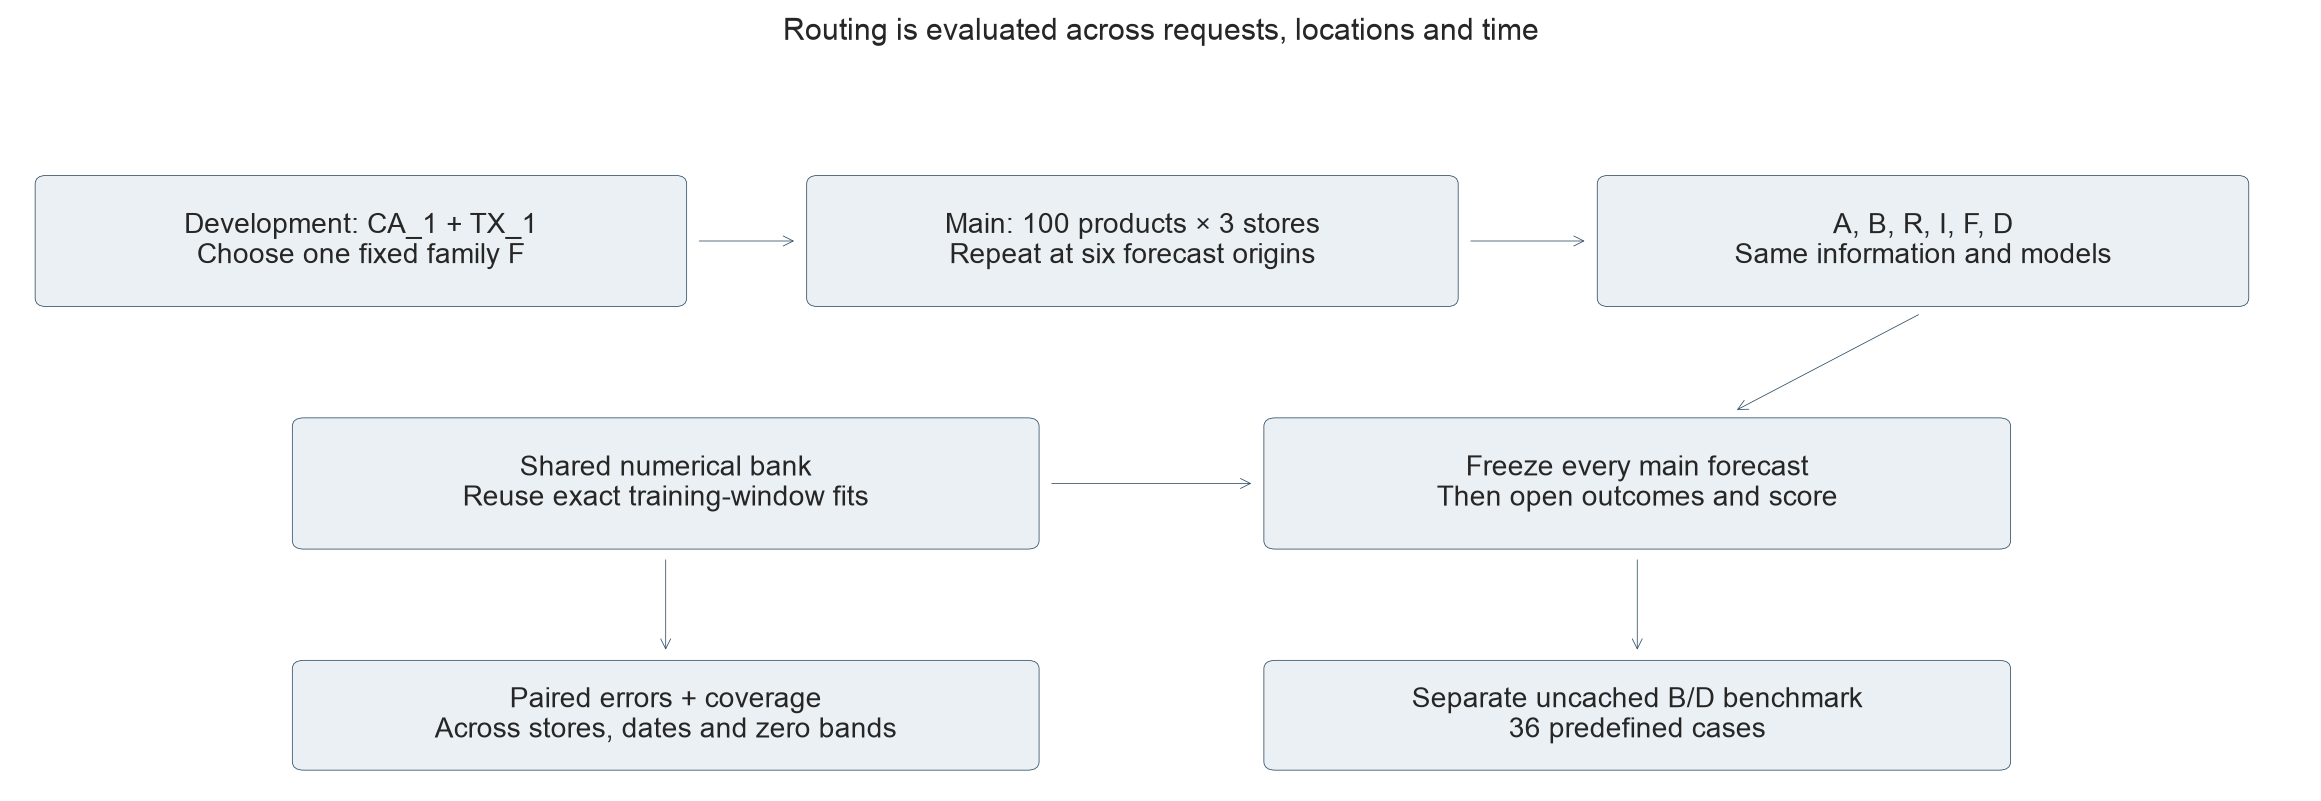

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-graph1.png')

In [5]:
assets.save(publication.architecture(CFG), "graph", panel.HEADINGS[0], "study-diagram",
            "Development chooses F; main evaluation repeats; actual runtime is measured separately.")

Graph 1 separates development choice, repeated forecasting and work measurement.
Development selects one fixed family F. Main evaluation compares F with routing and
other controls. The numerical bank shares fits, not outcome-informed decisions.

All main forecasts are frozen before scoring. A separate uncached benchmark measures
36 paired B/D executions. Looking up a forecast already in a shared bank is cheap;
that lookup time would be a misleading estimate of a standalone workflow's runtime.

## Build a panel without looking at future outcomes

In [6]:
data = panel.load_data()
assert data.manifest["protocol_hash"] == workflow.digest(protocol)
print({k: data.manifest[k] for k in ("items", "series", "days", "rows", "development_cases", "main_cases")})

{'items': 100, 'series': 300, 'days': 701, 'rows': 210300, 'development_cases': 600, 'main_cases': 1800}


The bundled panel makes reader execution independent of the raw M5 archive and
companion repository. Loading checks hashes, complete calendars, membership and
nonnegative integer sales. Missing rows are rejected rather than zero-filled.

There are 100 item IDs in CA_1, TX_1 and WI_1, each with 701 dates from 25 May 2014
through 24 April 2016. Rows do not prove inventory availability or true product age.
The target is recorded sales. The [M5 organizers](https://github.com/Mcompetitions/M5-methods)
document the original data.

In [7]:
first_main = next(c for c in data.cases if c["role"] == "main")
first_view = panel.view(data, first_main)
visible = workflow.as_series(first_view["history"])
print(first_main)
print(visible.head(3).to_string())
print("Visible dates:", visible.index[0].date(), "to", visible.index[-1].date(), "| n =", len(visible))

{'series_id': 'FOODS_1_044_CA_1_validation', 'item_id': 'FOODS_1_044', 'department': 'FOODS_1', 'store': 'CA_1', 'state': 'CA', 'role': 'main', 'day': 1745, 'as_of': '2015-11-08', 'case_id': 'P02-M-1745-FOODS_1_044-CA_1'}
2014-08-17    3.0
2014-08-18    2.0
2014-08-19    4.0
Visible dates: 2014-08-17 to 2015-11-08 | n = 449


A case identifies the product, store and forecast origin. Its restricted view
contains 449 observations ending at that origin. `as_series` restores a dated pandas
Series; `head(3)` prints a small sanity check without rendering an extra table.

Sampling used department quotas and a fixed item-ID hash ranking, excluding the
original twelve products. No future sales or method winner determined membership.
Using the same products across locations helps inspect store differences. This
balanced teaching cohort does not represent sales-volume or revenue weighting.

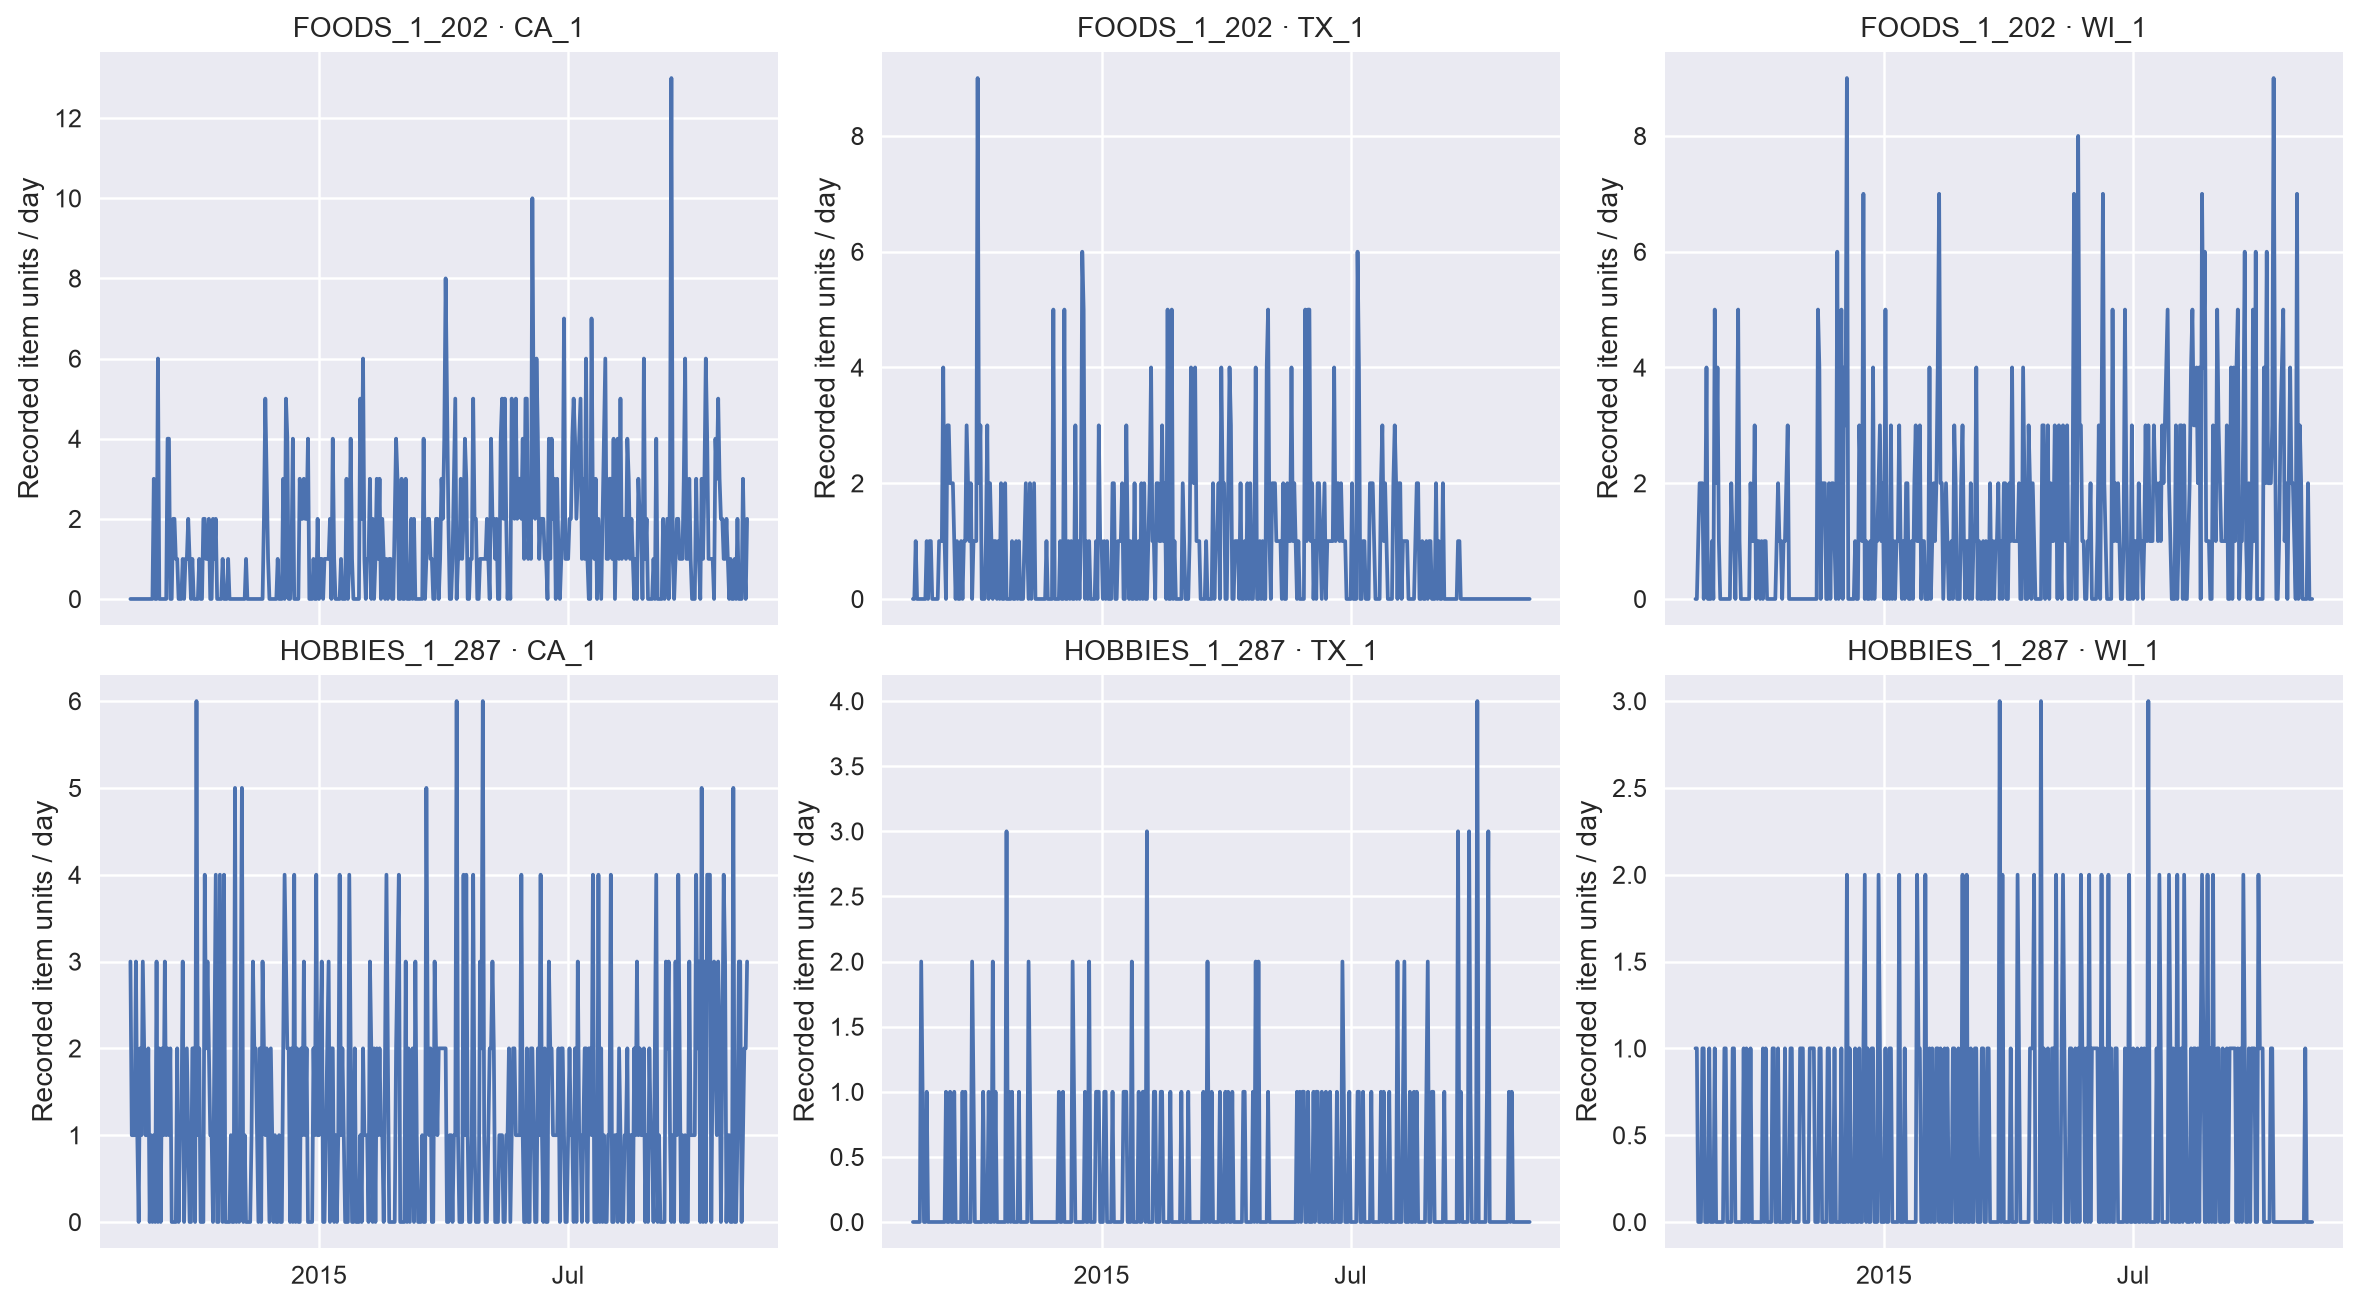

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-graph2.png')

In [8]:
assets.save(publication.raw_histories(CFG, data, protocol), "graph", panel.HEADINGS[1], "raw-histories",
            "Two hash-selected items across three stores; only their permitted pre-origin histories appear.")

Graph 2 shows raw histories before fitting. Both item IDs were chosen by hash in
declared departments, not because a method performed well or the plot looked persuasive.
Every panel ends at the first main origin; no forecast outcome is shown.

Y-axis scales vary with sales volume and quantities are recorded item units per day.
The plots illustrate what is being forecast. Differences across stores do not yet
establish useful routing, and zeros alone do not identify closures or stockouts.

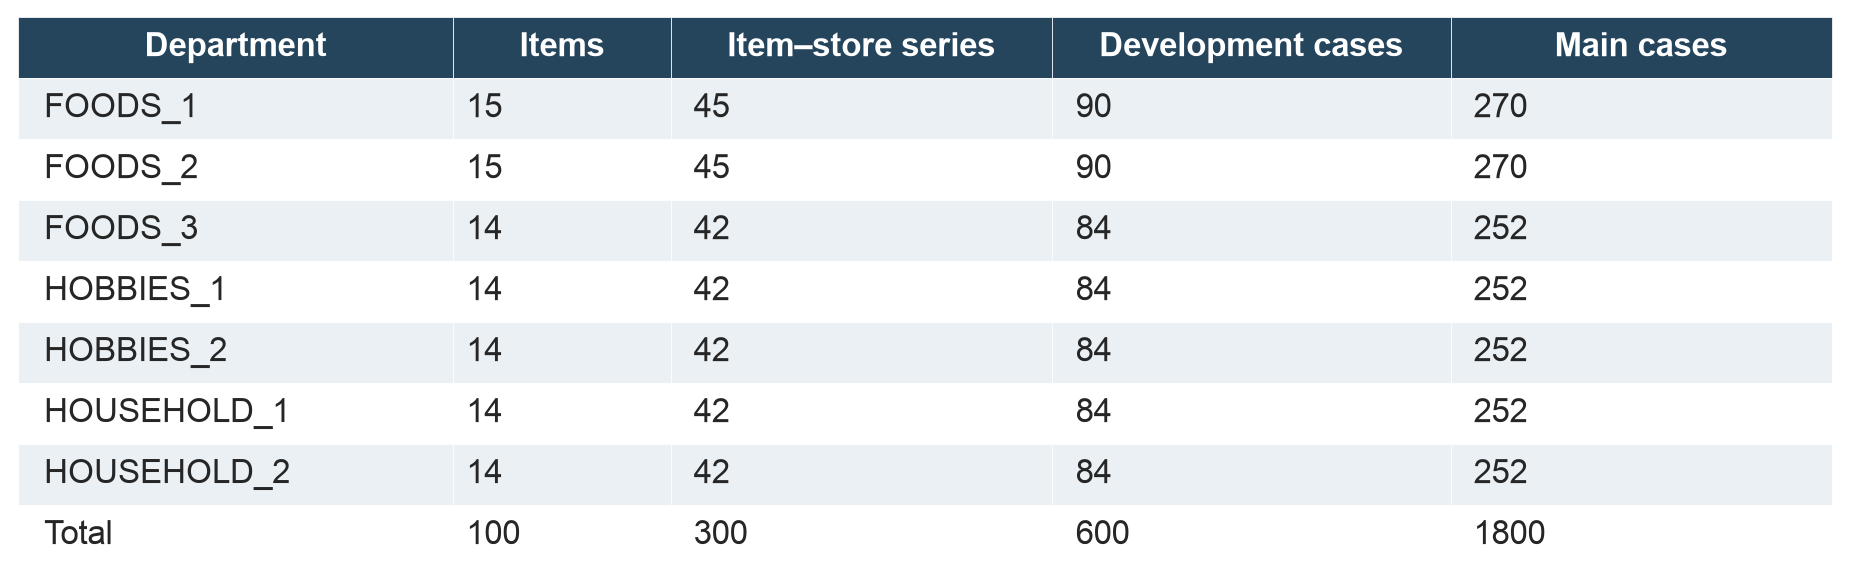

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-table1.png')

In [9]:
assets.table(publication.cohort_table(protocol), panel.HEADINGS[1], "cohort-table",
             "Department quotas and declared product–store–origin counts.")

Table 1 shows the cohort before scoring. Two departments contribute 15 items and
the other five contribute 14. Each item contributes three store series, six development
cases across two stores, and eighteen main cases across three stores.

The resulting 600 development and 1,800 main cases contain repeated observations of
the same items. They are not 2,400 independent products. Department quotas provide
coverage of categories but do not match population shares. Counts remain integers.

## Separate workflow selection from forecast evaluation

A is seasonal naive. B applies the existing zero-frequency rule. R always uses the
regular family; I always uses the intermittent family. F chooses R or I once on
development errors. D tests all three numerical methods on past validation folds.

At each outer origin, B selects intermittent if twice the last 365 days' zero count
is at least the observed count; otherwise it selects regular. The chosen family then
selects a numerical method by mean internal-validation RMSE.

The next 28 days evaluate the complete decision. This is distinct from the inner
folds used for candidate selection, following [rolling-origin evaluation](https://otexts.com/fpp3/toolbox.html#time-series-cross-validation).
The original notebook's three validation folds were not three outer evaluations.

In [10]:
print("Development origins:", protocol["development_origins"])
print("Main origins:", protocol["main_origins"])
print("WI_1 contributes development cases:", any(c["store"] == "WI_1" for c in data.cases if c["role"] == "development"))

Development origins: ['2015-08-16', '2015-09-13', '2015-10-11']
Main origins: ['2015-11-08', '2015-12-06', '2016-01-03', '2016-01-31', '2016-02-28', '2016-03-27']
WI_1 contributes development cases: False


Development origins are 16 August, 13 September and 11 October 2015. Six main origins
run from 8 November 2015 to 27 March 2016, each separated by 28 days. Main horizons do
not overlap; their training windows do.

WI_1 supplies no development error for choosing F. This tests geographic robustness
of a fixed rule, rather than generalization of a newly learned router. The final
development target ends at the first main origin and is then legitimately available.

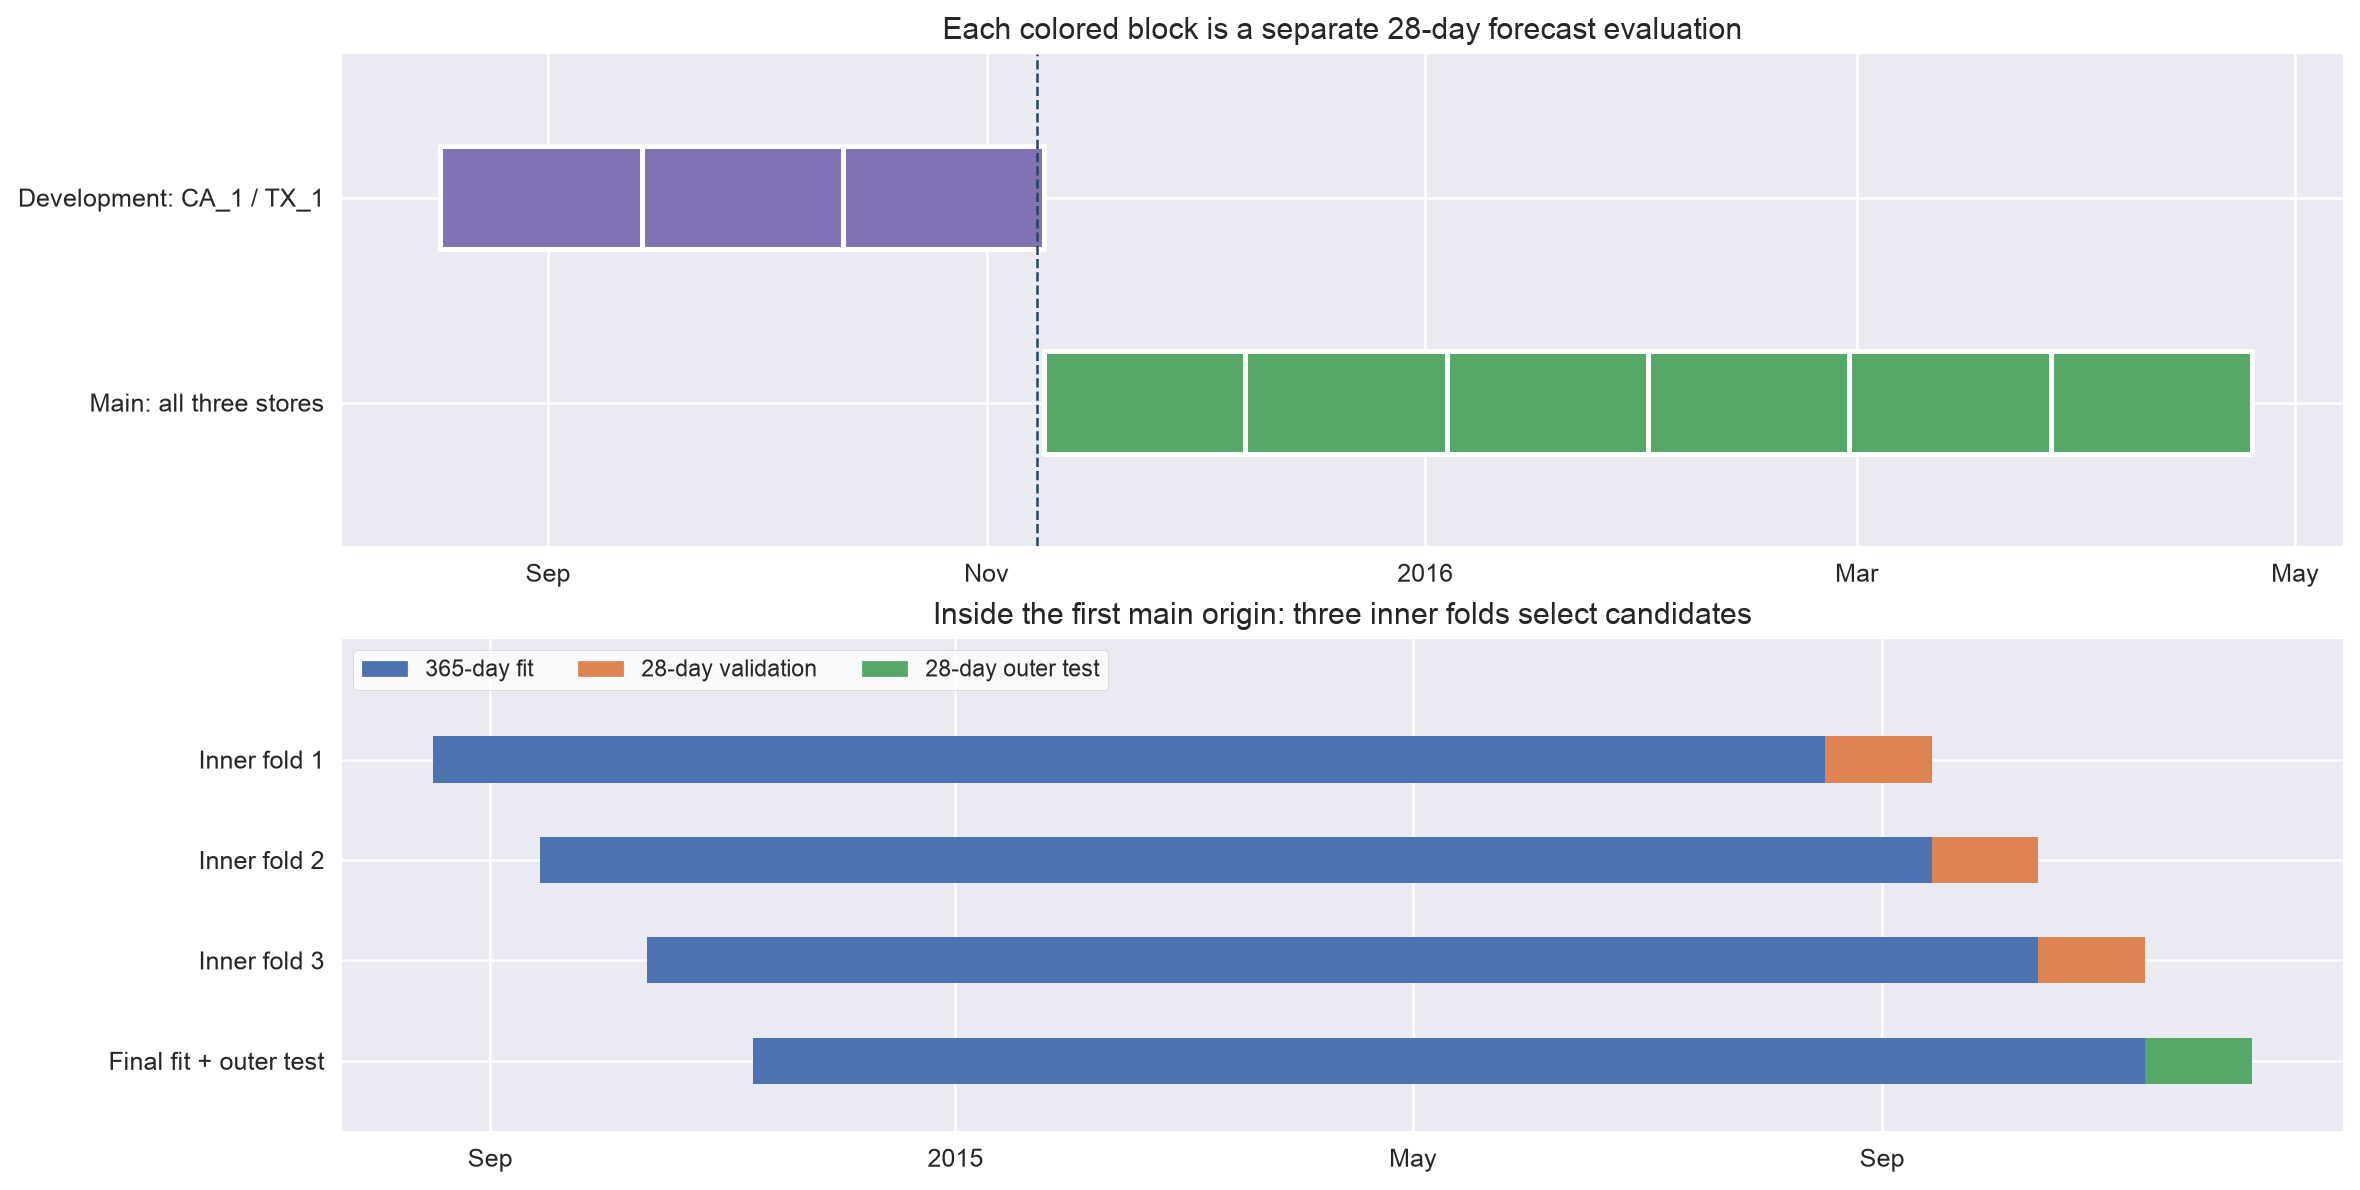

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-graph3.png')

In [11]:
assets.save(publication.timeline(CFG, protocol), "graph", panel.HEADINGS[2], "evaluation-calendar",
            "Outer development/main horizons and the inner folds at one issue date.")

Graph 3 shows two evaluation levels. The top panel marks issue dates and the next
28 days. The bottom panel opens one origin to show three 365-day fits, their internal
validation blocks, and the final fit followed by the outer test.

At later origins, observations that were earlier test outcomes have become history.
That is valid sequential forecasting. The fixed rule and comparator must nevertheless
remain fixed: earlier main results cannot be used to retune them during this study.

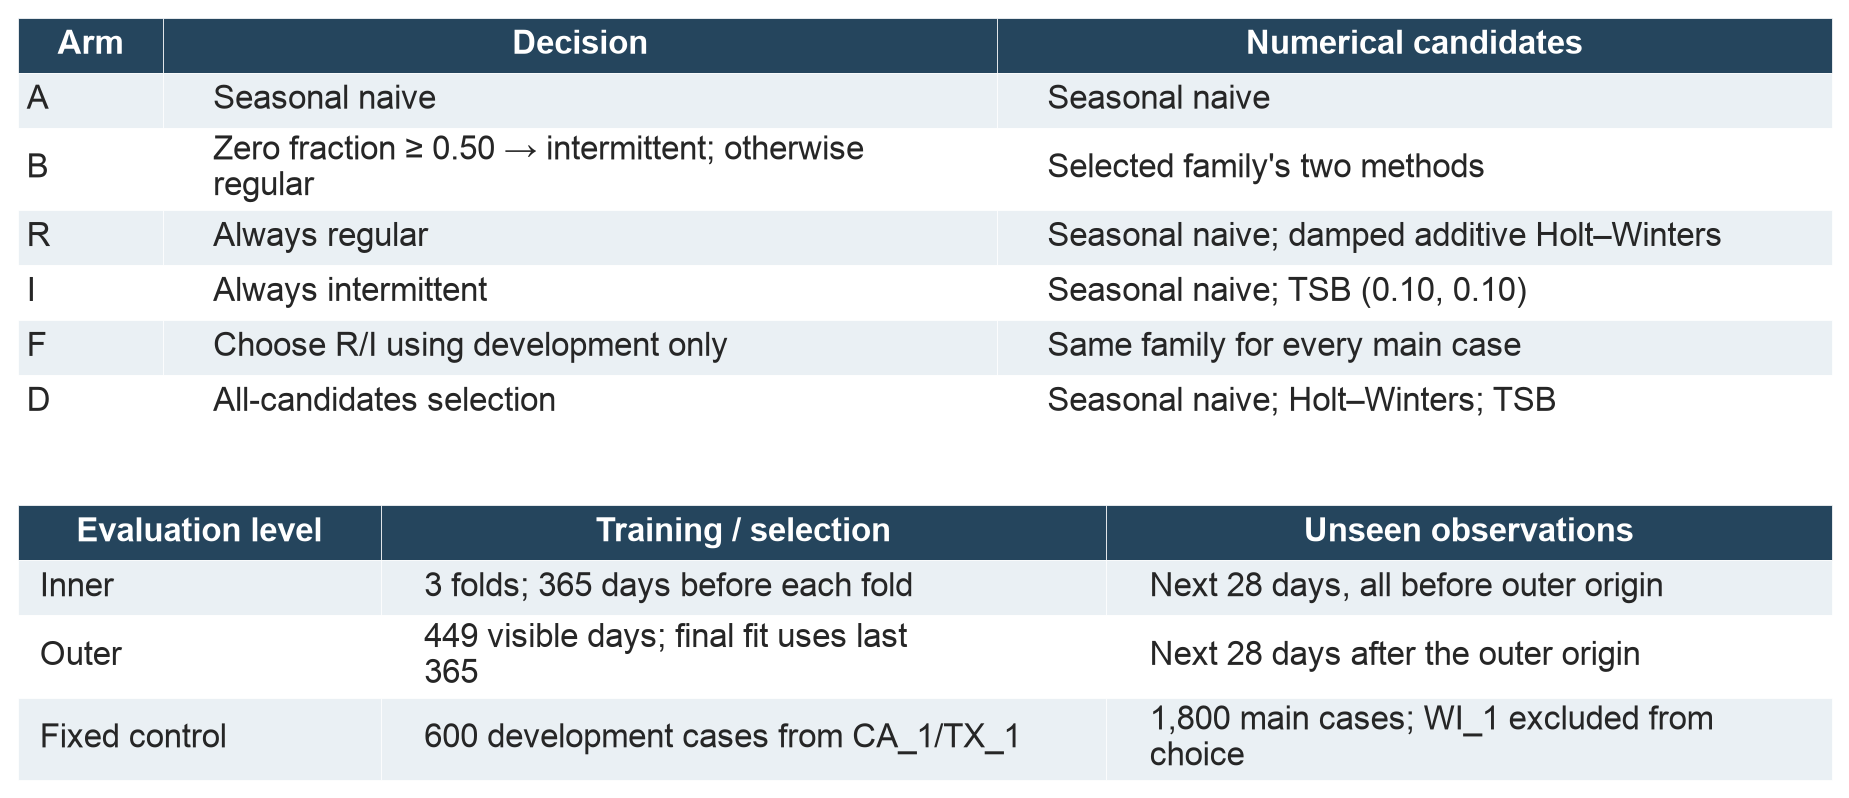

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-table2.png')

In [12]:
assets.table(publication.protocol_table(), panel.HEADINGS[2], "protocol-table",
             "Six arms share numerical methods, information and failure rules.")

Table 2 fixes the comparisons before fitting. B versus A alone would mix useful
routing with adding stronger models. R/I hold the family fixed, F chooses that fixed
family using earlier evidence, and D examines the cost of pruning candidates.

Each arm shares convergence checks, date/finite-output validation, clipping and
seasonal-naive fallback. D also selects using past folds; it is not a final-outcome
oracle. F cannot change family for each main store or after seeing the main winner.

In [13]:
bank = panel.FitBank()  # New empty bank; no saved numerical predictions are loaded.
development_cases = [c for c in data.cases if c["role"] == "development"]
development_frozen = panel.freeze_cases(data, development_cases, bank, progress=print)
panel.write(CFG.example_folder / "reader_development_frozen.json.gz", development_frozen.data)
print("Development forecasts frozen; unique fits:", len(bank.fits))

/Users/kbanachewicz/Documents/agentic-time-series-forecasting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


development 2015-08-16: 50/600 cases; 600 unique fits
development 2015-08-16: 100/600 cases; 1200 unique fits
development 2015-08-16: 150/600 cases; 1800 unique fits
development 2015-08-16: 200/600 cases; 2400 unique fits
development 2015-09-13: 250/600 cases; 2550 unique fits
development 2015-09-13: 300/600 cases; 2700 unique fits
development 2015-09-13: 350/600 cases; 2850 unique fits
development 2015-09-13: 400/600 cases; 3000 unique fits
development 2015-10-11: 450/600 cases; 3150 unique fits
development 2015-10-11: 500/600 cases; 3300 unique fits
development 2015-10-11: 550/600 cases; 3450 unique fits
development 2015-10-11: 600/600 cases; 3600 unique fits
Development forecasts frozen; unique fits: 3600


This cell recomputes development forecasts. Bank keys contain exact training
values/dates, the method, configuration and package versions. Identical windows can
be reused across arms and origins; different training values invalidate the key.

The bank stores numerical fits, not routes or final-outcome winners. Pure selection
reconstructs each arm from those records. The frozen development record is saved
before its outer outcomes are read. Shared computation is recorded separately from
the logical number of fits each standalone workflow would request.

In [14]:
development = panel.score(development_frozen, data)
fixed = panel.select_fixed(development)
panel.write(CFG.example_folder / "reader_development_results.json.gz", development)
panel.write(CFG.example_folder / "reader_fixed_workflow.json", fixed)
assert fixed == read_record("fixed_workflow.json")
print(json.dumps(fixed, indent=2))

{
  "version": "module02-panel-v1",
  "selected_arm": "I",
  "family": "intermittent",
  "common_scaled_n": 597,
  "eligible_n": 600,
  "macro_mase": {
    "R": 1.0056522662696092,
    "I": 1.0031411835243755
  },
  "development_result_hash": "002adb938dcf4553454e934628409a360ef1a96f610d44d678e658220c633815",
  "tie_order": [
    "R",
    "I"
  ]
}


Only now are development outcomes scored. F selects the lower R/I macro MASE on
the same delivered positive-scale cases. Ties choose R first; no eligible evidence
causes a visible failure. WI_1 and main errors cannot enter the choice.

Here 597 of 600 development cases have defined scales. I scores 1.00314, R 1.00565,
so F freezes intermittent. The difference is small; both fixed-family controls remain
visible in the main study. Fresh recomputation must match the original author choice.

In [15]:
main_cases = [c for c in data.cases if c["role"] == "main"]
assert len(main_cases) == 1800
main_rows = []
print("Main grid:", len({c["item_id"] for c in main_cases}), "products ×", len(panel.STORES), "stores ×", len(panel.MAIN_DAYS), "origins")
print("F is frozen as:", fixed["selected_arm"])

Main grid: 100 products × 3 stores × 6 origins
F is frozen as: I


The full main grid is declared before scoring. F uses the same fixed family at
every main store/date. B will recalculate evidence and route at each issue date.

The next six cells batch execution by origin for visible progress and checkpoints.
They extend the development bank where training inputs are exactly identical. This
reduces the cost of reproducing the study. It is not evidence that B alone performs
all shared work at the bank's lookup speed.

## Repeat routing across products, stores and origins

In [16]:
origin_cases = [c for c in main_cases if c["day"] == 1745]
batch = panel.freeze_cases(data, origin_cases, bank, fixed["selected_arm"], progress=print)
panel.write(CFG.example_folder / "reader_batches/main-1745.json.gz", batch.data)
main_rows.extend(batch.data["rows"])
print("Frozen main cases so far:", len(main_rows))

main 2015-11-08: 50/300 cases; 3894 unique fits
main 2015-11-08: 100/300 cases; 4197 unique fits
main 2015-11-08: 150/300 cases; 4500 unique fits
main 2015-11-08: 200/300 cases; 4794 unique fits
main 2015-11-08: 250/300 cases; 5097 unique fits
main 2015-11-08: 300/300 cases; 5400 unique fits
Frozen main cases so far: 300


Batch 1 recomputes all 300 cases at this origin. Every request first receives
its restricted 449-day history. The shared rule fixes B's family before candidate
comparisons are available. Past validation chooses a method; the final fit uses the
last 365 observations.

The checkpoint contains predictions and provenance, not outer scores. No main outer
actual is opened in this cell. Earlier calendar observations may enter a later
history, which is valid at that later origin. Every batch is recomputed from a clean
execution rather than trusting previous reader checkpoints.

In [17]:
origin_cases = [c for c in main_cases if c["day"] == 1773]
batch = panel.freeze_cases(data, origin_cases, bank, fixed["selected_arm"], progress=print)
panel.write(CFG.example_folder / "reader_batches/main-1773.json.gz", batch.data)
main_rows.extend(batch.data["rows"])
print("Frozen main cases so far:", len(main_rows))

main 2015-12-06: 50/300 cases; 5550 unique fits
main 2015-12-06: 100/300 cases; 5700 unique fits
main 2015-12-06: 150/300 cases; 5850 unique fits
main 2015-12-06: 200/300 cases; 6000 unique fits
main 2015-12-06: 250/300 cases; 6150 unique fits
main 2015-12-06: 300/300 cases; 6300 unique fits
Frozen main cases so far: 600


Batch 2 recomputes all 300 cases at this origin. Every request first receives
its restricted 449-day history. The shared rule fixes B's family before candidate
comparisons are available. Past validation chooses a method; the final fit uses the
last 365 observations.

The checkpoint contains predictions and provenance, not outer scores. No main outer
actual is opened in this cell. Earlier calendar observations may enter a later
history, which is valid at that later origin. Every batch is recomputed from a clean
execution rather than trusting previous reader checkpoints.

In [18]:
origin_cases = [c for c in main_cases if c["day"] == 1801]
batch = panel.freeze_cases(data, origin_cases, bank, fixed["selected_arm"], progress=print)
panel.write(CFG.example_folder / "reader_batches/main-1801.json.gz", batch.data)
main_rows.extend(batch.data["rows"])
print("Frozen main cases so far:", len(main_rows))

main 2016-01-03: 50/300 cases; 6450 unique fits
main 2016-01-03: 100/300 cases; 6600 unique fits
main 2016-01-03: 150/300 cases; 6750 unique fits
main 2016-01-03: 200/300 cases; 6900 unique fits
main 2016-01-03: 250/300 cases; 7050 unique fits
main 2016-01-03: 300/300 cases; 7200 unique fits
Frozen main cases so far: 900


Batch 3 recomputes all 300 cases at this origin. Every request first receives
its restricted 449-day history. The shared rule fixes B's family before candidate
comparisons are available. Past validation chooses a method; the final fit uses the
last 365 observations.

The checkpoint contains predictions and provenance, not outer scores. No main outer
actual is opened in this cell. Earlier calendar observations may enter a later
history, which is valid at that later origin. Every batch is recomputed from a clean
execution rather than trusting previous reader checkpoints.

In [19]:
origin_cases = [c for c in main_cases if c["day"] == 1829]
batch = panel.freeze_cases(data, origin_cases, bank, fixed["selected_arm"], progress=print)
panel.write(CFG.example_folder / "reader_batches/main-1829.json.gz", batch.data)
main_rows.extend(batch.data["rows"])
print("Frozen main cases so far:", len(main_rows))

main 2016-01-31: 50/300 cases; 7350 unique fits
main 2016-01-31: 100/300 cases; 7500 unique fits
main 2016-01-31: 150/300 cases; 7650 unique fits
main 2016-01-31: 200/300 cases; 7800 unique fits
main 2016-01-31: 250/300 cases; 7950 unique fits
main 2016-01-31: 300/300 cases; 8100 unique fits
Frozen main cases so far: 1200


Batch 4 recomputes all 300 cases at this origin. Every request first receives
its restricted 449-day history. The shared rule fixes B's family before candidate
comparisons are available. Past validation chooses a method; the final fit uses the
last 365 observations.

The checkpoint contains predictions and provenance, not outer scores. No main outer
actual is opened in this cell. Earlier calendar observations may enter a later
history, which is valid at that later origin. Every batch is recomputed from a clean
execution rather than trusting previous reader checkpoints.

In [20]:
origin_cases = [c for c in main_cases if c["day"] == 1857]
batch = panel.freeze_cases(data, origin_cases, bank, fixed["selected_arm"], progress=print)
panel.write(CFG.example_folder / "reader_batches/main-1857.json.gz", batch.data)
main_rows.extend(batch.data["rows"])
print("Frozen main cases so far:", len(main_rows))

main 2016-02-28: 50/300 cases; 8250 unique fits
main 2016-02-28: 100/300 cases; 8400 unique fits
main 2016-02-28: 150/300 cases; 8550 unique fits
main 2016-02-28: 200/300 cases; 8700 unique fits
main 2016-02-28: 250/300 cases; 8850 unique fits
main 2016-02-28: 300/300 cases; 9000 unique fits
Frozen main cases so far: 1500


Batch 5 recomputes all 300 cases at this origin. Every request first receives
its restricted 449-day history. The shared rule fixes B's family before candidate
comparisons are available. Past validation chooses a method; the final fit uses the
last 365 observations.

The checkpoint contains predictions and provenance, not outer scores. No main outer
actual is opened in this cell. Earlier calendar observations may enter a later
history, which is valid at that later origin. Every batch is recomputed from a clean
execution rather than trusting previous reader checkpoints.

In [21]:
origin_cases = [c for c in main_cases if c["day"] == 1885]
batch = panel.freeze_cases(data, origin_cases, bank, fixed["selected_arm"], progress=print)
panel.write(CFG.example_folder / "reader_batches/main-1885.json.gz", batch.data)
main_rows.extend(batch.data["rows"])
print("Frozen main cases so far:", len(main_rows))

main 2016-03-27: 50/300 cases; 9150 unique fits
main 2016-03-27: 100/300 cases; 9300 unique fits
main 2016-03-27: 150/300 cases; 9450 unique fits
main 2016-03-27: 200/300 cases; 9600 unique fits
main 2016-03-27: 250/300 cases; 9750 unique fits
main 2016-03-27: 300/300 cases; 9900 unique fits
Frozen main cases so far: 1800


Batch 6 recomputes all 300 cases at this origin. Every request first receives
its restricted 449-day history. The shared rule fixes B's family before candidate
comparisons are available. Past validation chooses a method; the final fit uses the
last 365 observations.

The checkpoint contains predictions and provenance, not outer scores. No main outer
actual is opened in this cell. Earlier calendar observations may enter a later
history, which is valid at that later origin. Every batch is recomputed from a clean
execution rather than trusting previous reader checkpoints.

In [22]:
frozen = FrozenJSON.of({"version": panel.VERSION, "rows": main_rows})
panel.write(CFG.example_folder / "reader_frozen_forecasts.json.gz", frozen.data)
panel.write(CFG.example_folder / "reader_fit_bank.json.gz", bank.snapshot())
assert workflow.digest(workflow.semantic(frozen.data)) == author_run["frozen_semantic_hash"]
assert workflow.digest(workflow.semantic(bank.snapshot())) == author_run["bank_semantic_hash"]
print("All main forecasts frozen:", len(main_rows), "| Unique numerical fits:", len(bank.fits))

All main forecasts frozen: 1800 | Unique numerical fits: 9900


Every main forecast exists before scoring. The immutable record contains evidence,
view hashes, routes, past validation scores and dated predictions, with no outer
actuals. A fresh copy will be passed to the scorer.

Hashes compare these newly computed predictions and bank records with the author
run. Durations are excluded from semantic equality; failures, warnings and forecasts
remain included. The bank makes 9,900 unique attempts, serving 28,800 lookups through
18,900 exact cache hits across development and main.

In [23]:
result = panel.score(frozen, data)
panel.write(CFG.example_folder / "reader_results.json.gz", result)
assert result["scored_after_freeze"]
assert workflow.digest(workflow.semantic(result)) == author_run["result_semantic_hash"]
print("Scored main cases:", len(result["rows"]))

Scored main cases: 1800


The scorer now opens the next 28 actual observations. MAE averages absolute errors;
RMSE emphasizes large errors. MASE divides MAE by the training window's mean absolute
lag-7 difference. Its scale never uses this forecast's outer outcomes.

Undefined scales stay N/A and missing forecasts receive no score. Here every arm
delivers all 1,800 main cases, all with positive scales. This differs from the three
undefined development scales; those cases remained recorded while being excluded
from F's MASE comparison.

## Where does routing help, and where does it hurt?

In [24]:
summary = panel.summarize(result)
panel.write(CFG.example_folder / "reader_summary.json", summary)
assert summary == read_record("summary.json")
print(json.dumps(summary["arms"], indent=2))

{
  "A": {
    "eligible_n": 1800,
    "delivered_n": 1800,
    "common_n": 1800,
    "scaled_n": 1800,
    "excluded_scale_n": 0,
    "macro_mase": 1.091838044688216,
    "delivered_macro_mae": 1.0863690476190475,
    "numerical_fallback_n": 0,
    "logical_fit_attempts": 1800
  },
  "B": {
    "eligible_n": 1800,
    "delivered_n": 1800,
    "common_n": 1800,
    "scaled_n": 1800,
    "excluded_scale_n": 0,
    "macro_mase": 0.968753559607997,
    "delivered_macro_mae": 0.8997720593983985,
    "numerical_fallback_n": 0,
    "logical_fit_attempts": 14291
  },
  "R": {
    "eligible_n": 1800,
    "delivered_n": 1800,
    "common_n": 1800,
    "scaled_n": 1800,
    "excluded_scale_n": 0,
    "macro_mase": 0.9699590862699371,
    "delivered_macro_mae": 0.89998844290486,
    "numerical_fallback_n": 0,
    "logical_fit_attempts": 14251
  },
  "I": {
    "eligible_n": 1800,
    "delivered_n": 1800,
    "common_n": 1800,
    "scaled_n": 1800,
    "excluded_scale_n": 0,
    "macro_mase": 0.97

Every headline MASE uses the identical listed case set. Common delivery and scale
counts are both 1,800, with no silent main exclusions. Macro MASE is A 1.09184,
B 0.96875, R 0.96996, I/F 0.97396 and D 0.96719.

B improves on F by about 0.54% of F's macro MASE. Always-regular R is also close, so
this is not a large gain over every fixed workflow. D has the lowest aggregate error.
MASE below one compares against historical scaling error; A's measured outer error
provides the direct seasonal-naive baseline comparison.

In [25]:
print("Paired contrasts:", json.dumps(summary["contrasts"], indent=2))
print("Item-block resampling:", json.dumps(summary["bootstrap"], indent=2))
print("Every B−F origin contrast is negative:", all(r["F"]["delta_mase"] < 0 for r in summary["by_origin"].values()))

Paired contrasts: {
  "F": {
    "eligible_n": 1800,
    "common_n": 1800,
    "scaled_n": 1800,
    "delta_mase": -0.005211214012632501,
    "delta_mae": -0.006854981142716416,
    "routing_wins": 354,
    "routing_losses": 251,
    "ties": 1195
  },
  "D": {
    "eligible_n": 1800,
    "common_n": 1800,
    "scaled_n": 1800,
    "delta_mase": 0.0015640125150956513,
    "delta_mae": 0.0034729343740680743,
    "routing_wins": 386,
    "routing_losses": 399,
    "ties": 1015
  }
}
Item-block resampling: {
  "F": {
    "item_blocks": 100,
    "repetitions": 2000,
    "valid_repetitions": 2000,
    "seed": 42,
    "low": -0.008840806350591411,
    "high": -0.0018165750822631912,
    "scope": "Item-block resampling conditional on these three stores and six origins; not independent daily-error inference."
  },
  "D": {
    "item_blocks": 100,
    "repetitions": 2000,
    "valid_repetitions": 2000,
    "seed": 42,
    "low": -0.003798108513901874,
    "high": 0.007254454702064925,
    "scope

The bootstrap resamples 100 item-ID blocks 2,000 times with seed 42. An item keeps
its stores/dates, and arm comparisons remain paired. Daily errors are not treated as
independent experiments.

The conditional 95% resampling interval for B−F is about −0.00884 to −0.00182 MASE;
for B−D it is −0.00380 to 0.00725. Shared shocks across items and only six adjacent
horizons limit broader inference. These intervals condition on the stores and dates;
an interval containing zero does not establish equivalence.

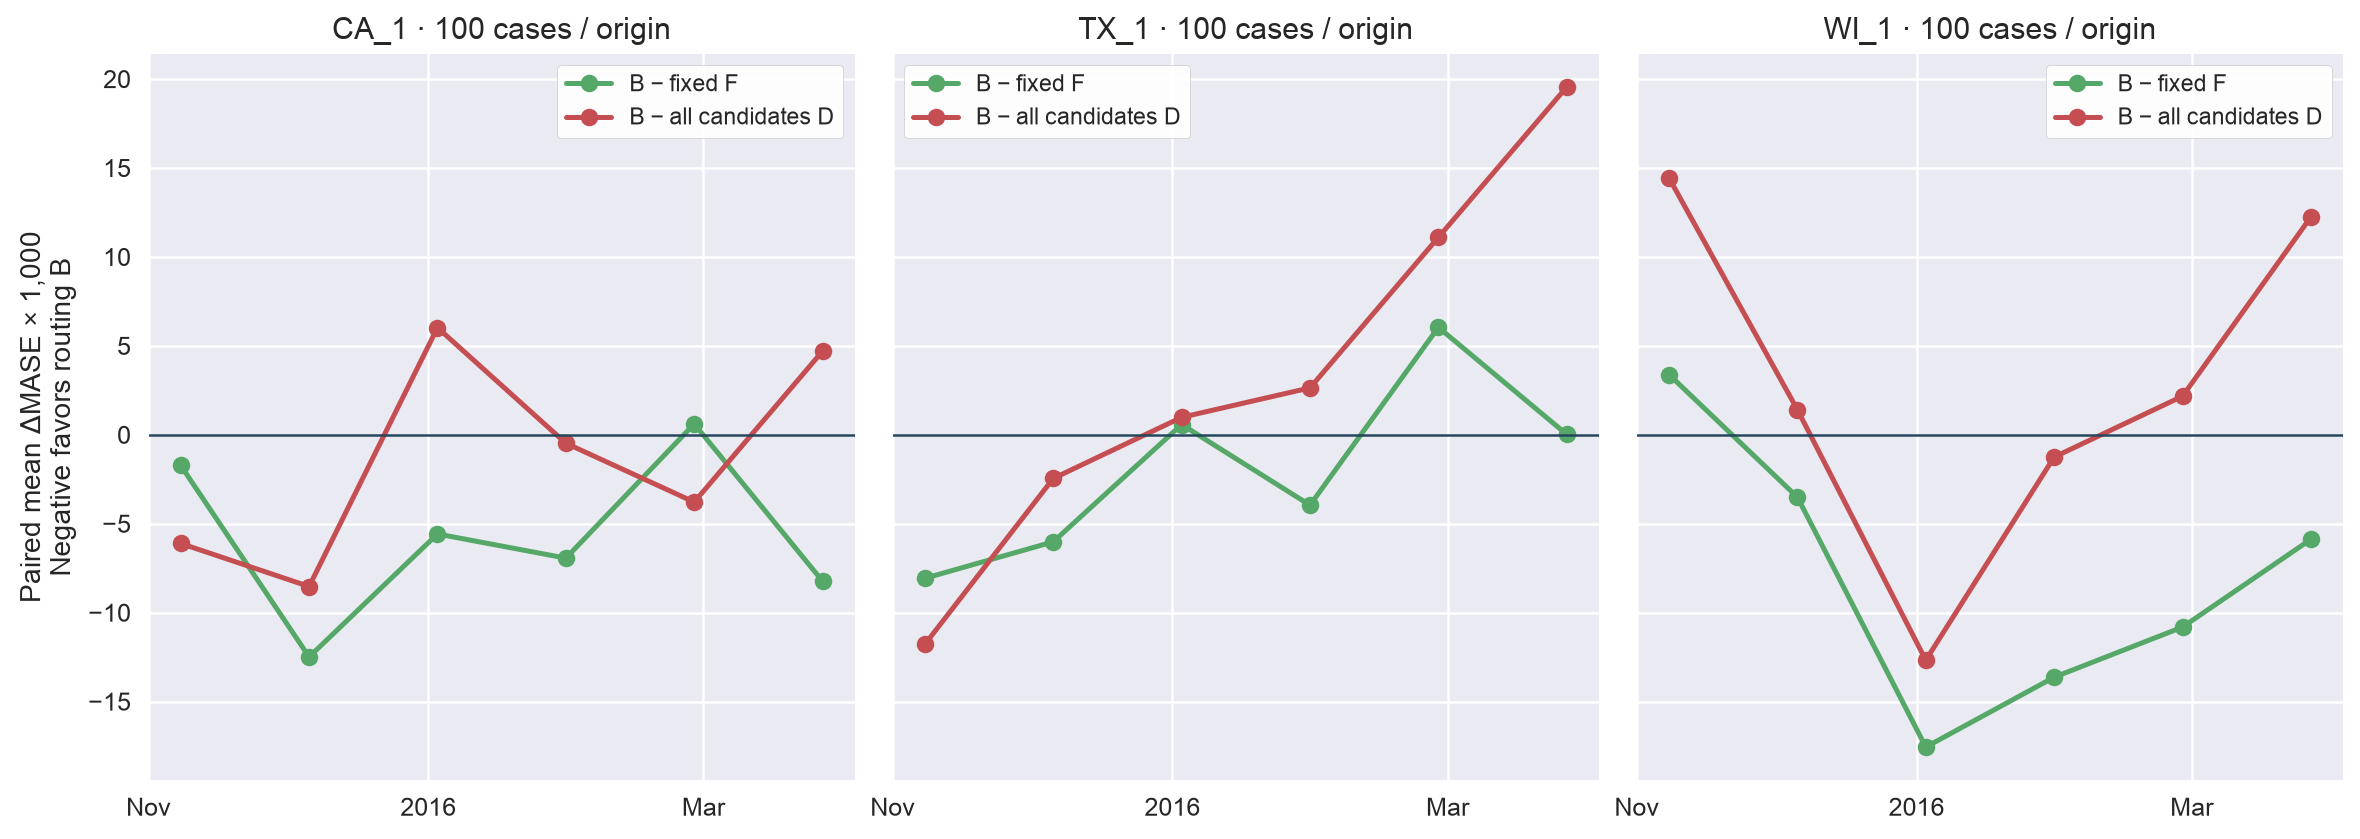

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-graph4.png')

In [26]:
assets.source_hash = workflow.digest(workflow.semantic(result))
assets.save(publication.error_by_origin(CFG, summary), "graph", panel.HEADINGS[4], "errors-by-origin",
            "Every predefined main store and date; negative paired differences favor B.")

Graph 4 displays all six dates in every store. Each point averages 100 paired
cases. Multiplying MASE differences by 1,000 makes the small changes readable without
rounding the calculations. Negative values favor B.

Average B−F MASE is negative in every store and aggregate origin. B−D changes sign
through time. MAE can differ because it weights items differently: February B−F MAE
is worse even though its MASE is lower. Unfavorable dates remain visible.

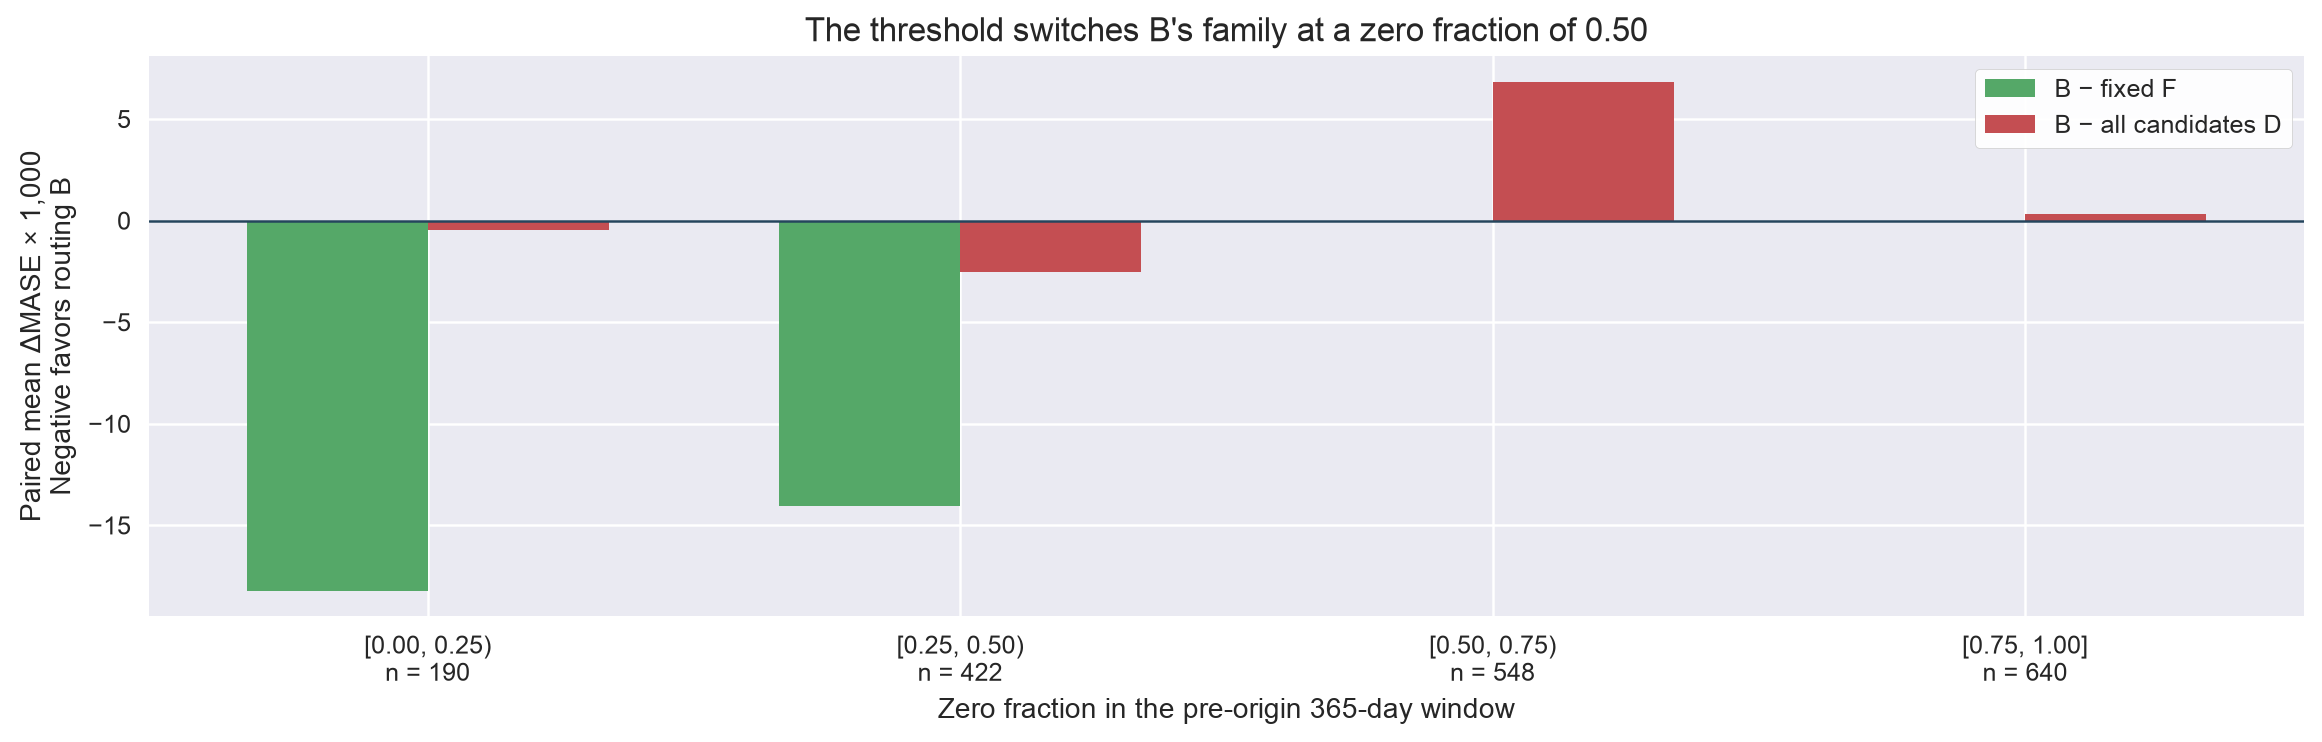

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-graph5.png')

In [27]:
assets.save(publication.error_by_band(CFG, summary), "graph", panel.HEADINGS[4], "errors-by-band",
            "Predeclared zero-fraction bands and their actual denominators.")

Graph 5 uses only pre-origin evidence to define the four fixed bands. Their counts
are 190, 422, 548 and 640. B chooses regular below a zero fraction of 0.50 and
intermittent at or above it.

Since F always uses intermittent, B and F are identical in the upper two bands by
construction. Those zero differences are not a discovery. The lower bands assess
switching families. This describes a fixed rule's behavior; it does not search for
a better threshold using main outcomes.

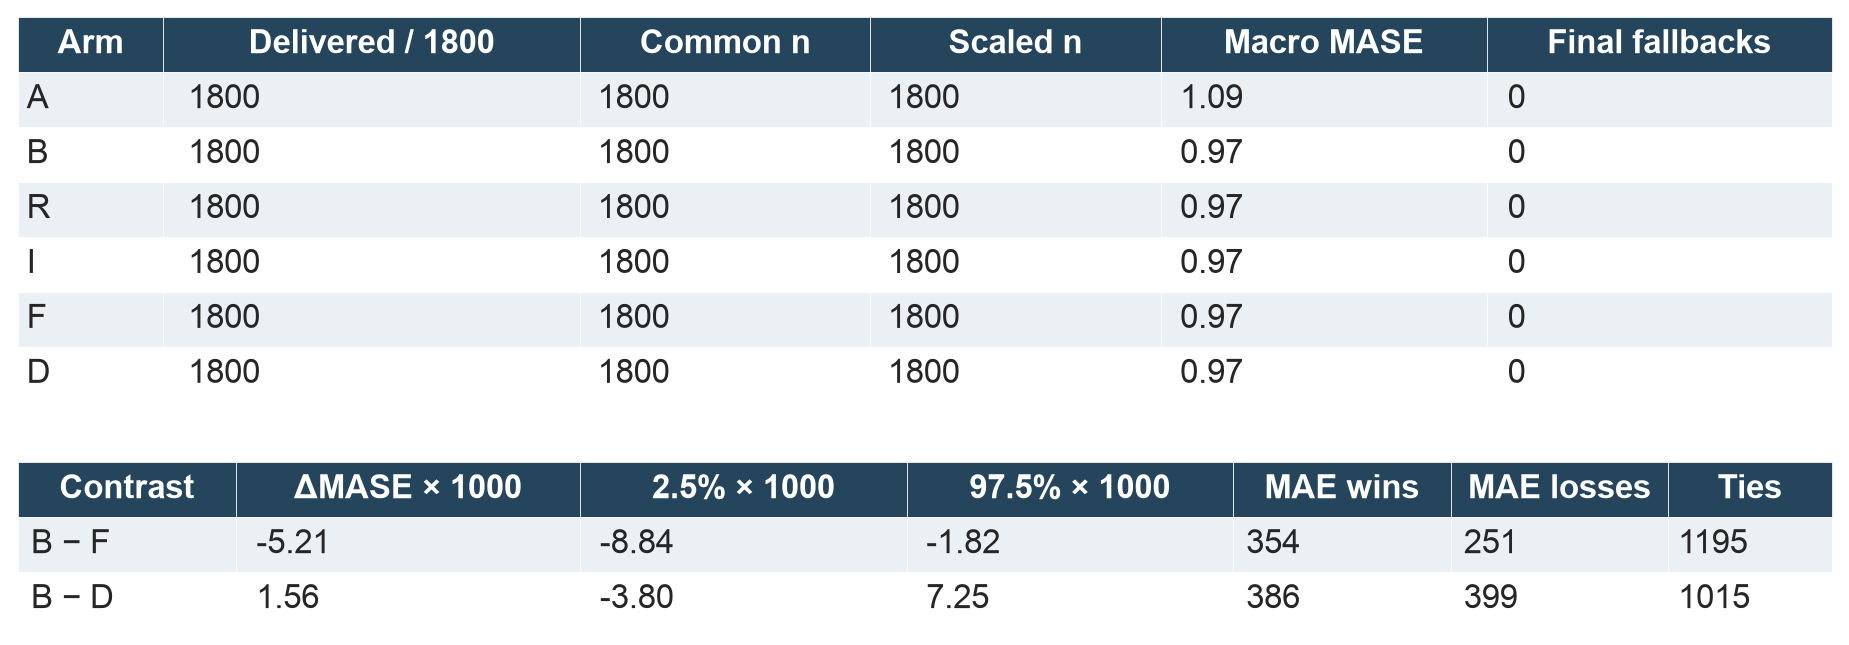

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-table3.png')

In [28]:
assets.table(publication.accuracy_table(summary), panel.HEADINGS[4], "accuracy-table",
             "Common-case accuracy; paired differences and conditional interval endpoints scaled by 1,000.")

Table floats retain exactly two display decimals, so several macro MASE values
appear as 0.97. The second block shows ΔMASE × 1,000 and similarly scaled conditional
interval endpoints. This exposes small differences while retaining calculation precision.

MAE wins/losses/ties are 354/251/1,195 for B versus F and 386/399/1,015 versus D.
Coverage is complete with no final numerical fallbacks. Six failed candidate fits in
the shared bank remain recorded: an ineligible candidate did not prevent delivery
through another method. Explanations and captions stay outside the image.

## How much work does routing save?

In [29]:
timing_cases = panel.timing_cases(data.cases, protocol)
reader_timings = panel.measure_uncached(data, timing_cases)
panel.write(CFG.example_folder / "reader_timings.json", reader_timings)
reader_work = panel.work_record(bank, result, reader_timings)
panel.write(CFG.example_folder / "reader_work.json", reader_work)
for row in reader_timings["rows"]:
    reference = next(r for r in result["rows"] if r["case"]["case_id"] == row["case_id"])
    for arm in ("B", "D"):
        assert row["arms"][arm]["forecast_hash"] == workflow.digest(reference["arms"][arm]["forecast"])
print("Current uncached timings:", json.dumps(reader_work["uncached_timing"], indent=2))

Current uncached timings: {
  "B": {
    "n": 36,
    "seconds": 2.5669534988701344,
    "median_seconds": 0.0019627289148047566,
    "fit_attempts": 286
  },
  "D": {
    "n": 36,
    "seconds": 5.008562455768697,
    "median_seconds": 0.12801189546007663,
    "fit_attempts": 394
  }
}


The 36 uncached cases use two preselected item IDs in all stores and origins.
B/D order alternates; imports/fitting are warmed on development data outside totals.
B includes profiling and dispatch. Prediction hashes must match the main results.

Fresh times vary by session. The next table uses the archived author's same-protocol
benchmark for stable publication values. It never adds timings from separate sessions.
Two products are a limited timing sample rather than a precise full-grid speed estimate.

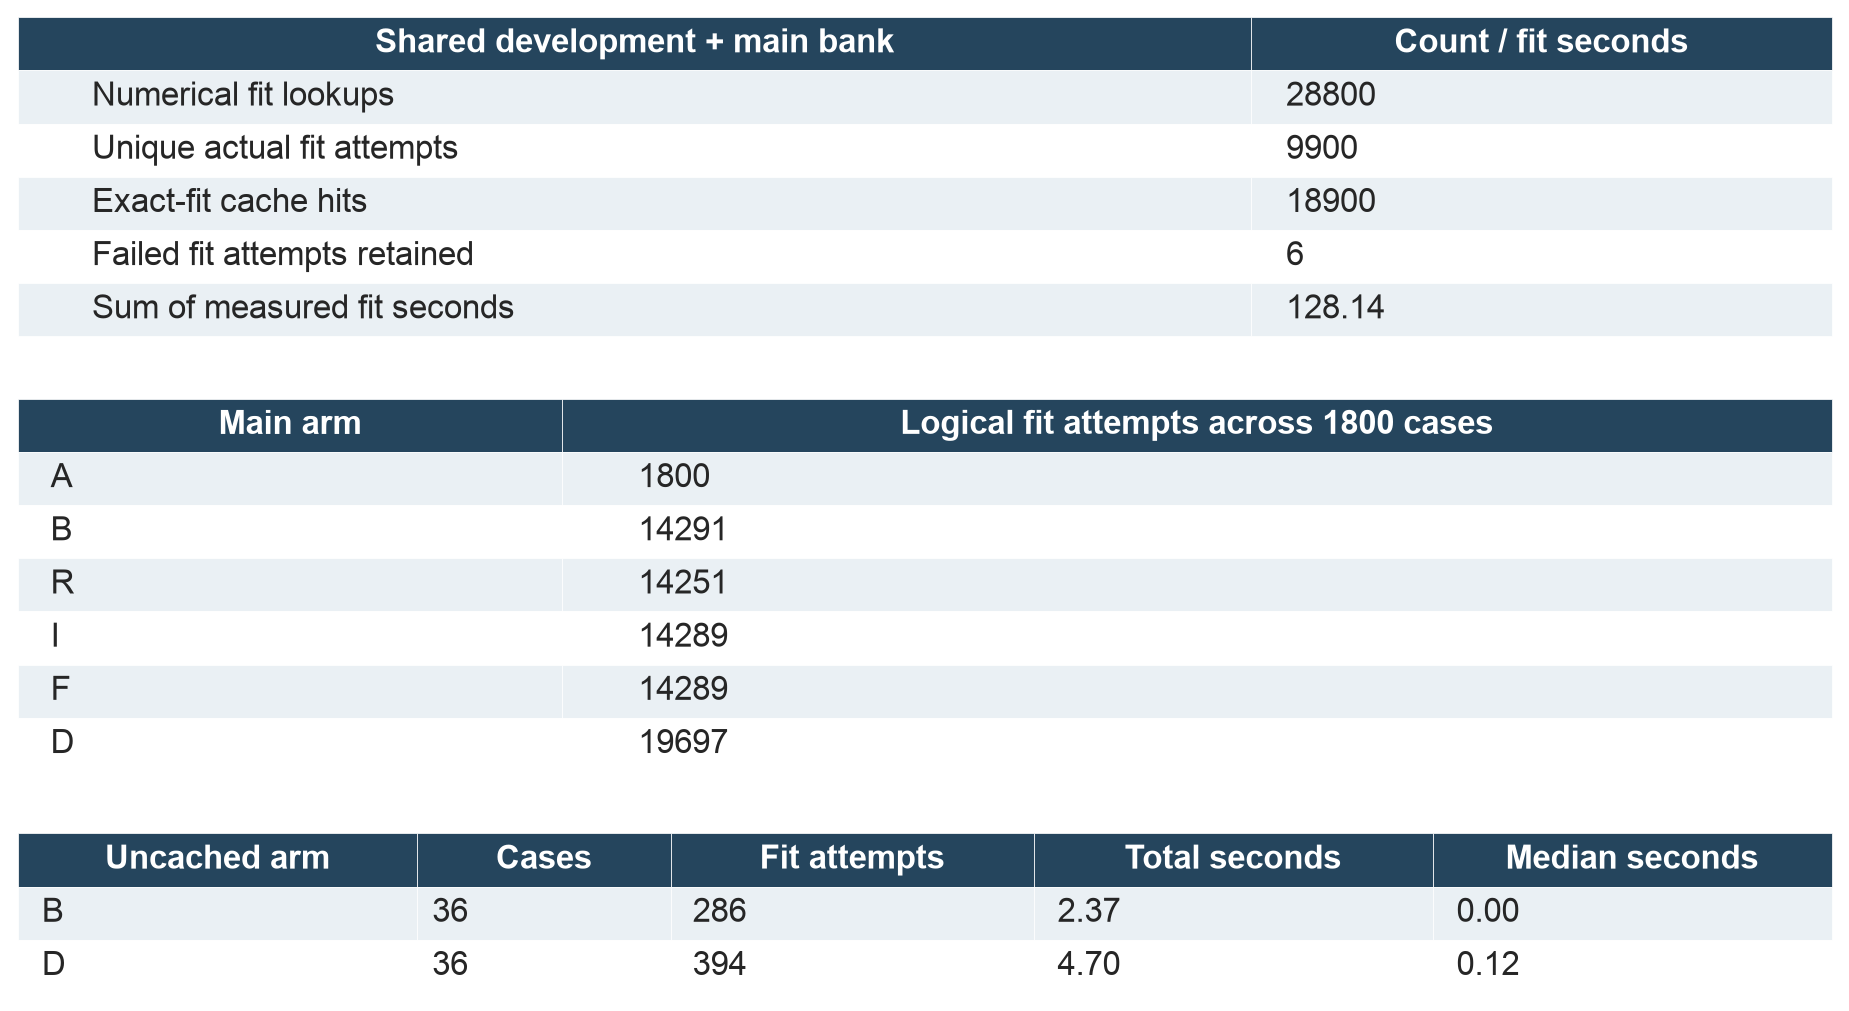

PosixPath('/Users/kbanachewicz/Documents/agentic-time-series-forecasting/graphs/module02-panel/atsf02-table4.png')

In [30]:
author_work = read_record("work.json")
assets.source_hash = workflow.digest(author_work)
assets.table(publication.work_table(author_work), panel.HEADINGS[5], "work-table",
             "Shared-bank work, logical main-arm budgets and archived uncached execution are separate.")

The first block counts the shared bank's actual attempts and lookups across both
periods. These costs cannot be assigned to B as if it independently produced the study.
The second block reconstructs logical main-arm work under standalone execution.

B requests 14,291 fits versus D's 19,697, or 27.45% fewer. In the archived uncached
subset, B/D made 286/394 attempts and took 2.37/4.70 seconds. These are local observations.
A tiny positive B median displays 0.00 under required formatting; stored precision is
preserved. All failed attempts remain counted.

## What does the larger experiment establish?

This broader study supports a narrow positive result for the existing deterministic
policy: B modestly improves on the development-selected fixed family and approaches
all-candidates selection with fewer logical fits. It also reveals how close
always-regular R comes, and where pruning removes useful candidates.

The cohort is retrospective, balanced by department, and limited to 100 products,
three stores and six adjacent horizons. WI_1 was excluded from choosing F; the routing
rule itself was already fixed. We do not establish an LLM advantage or measure analyst
explanation quality, true demand, uncertainty calibration or inventory value.

More products, locations and dates improved the evidence available for interpretation.
Full records preserve modest gains and losses. The threshold was never retuned to
make this study win; the same design would permit a negative conclusion.

In [31]:
verification = {
    "protocol_hash": workflow.digest(protocol),
    "development_cases": len(development["rows"]),
    "main_cases": len(result["rows"]),
    "frozen_semantic_hash": workflow.digest(workflow.semantic(frozen.data)),
    "result_semantic_hash": workflow.digest(workflow.semantic(result)),
    "bank_semantic_hash": workflow.digest(workflow.semantic(bank.snapshot())),
    "graphs": sum(a["kind"] == "graph" for a in assets.assets),
    "tables": sum(a["kind"] == "table" for a in assets.assets),
    "new_llm_calls": inference_guard.call_count,
}
assert verification["new_llm_calls"] == 0
assert (verification["graphs"], verification["tables"]) == (5, 4)
panel.write(CFG.example_folder / "recompute_verification.json", verification)
no_inference.stop()
print(json.dumps(verification, indent=2))

{
  "protocol_hash": "485573eaf454e41a3875f451990c7ac8cb1a22c6d3bb5e8df0a337d55c66ff4e",
  "development_cases": 600,
  "main_cases": 1800,
  "frozen_semantic_hash": "6bdb50a0f9e9c04d3572d0842bb07ecec7287124368c3b3311ce673be5eec2b6",
  "result_semantic_hash": "b9a7dab41f83104dfb320838c90bb9269d0331219bf90dac98d260bb8495d598",
  "bank_semantic_hash": "afc74bf0ec464cd8628b11836a3e86d1f53b50d5fece5a12d34ad2785c9bd9bc",
  "graphs": 5,
  "tables": 4,
  "new_llm_calls": 0
}


The final record binds the complete recomputed study to the protocol, author
predictions and nine exports. The publication verifier also checks independent error
arithmetic, clean execution, source integrity, relative links, section headings and
typed table formatting. Visual and semantic review remain explicit author checks.

After `uv sync --locked`, execute `.venv/bin/python -m scripts.execute_module02_panel`
from the repository root. The runner uses a clean kernel, recomputes all required fits
with exact sharing, and needs no raw archive, network or Ollama server. Author records
remain distinct from reader recomputation.